First 5 rows:
              area_type   availability                  location       size  \
0  Super built-up  Area         19-Dec  Electronic City Phase II      2 BHK   
1            Plot  Area  Ready To Move          Chikka Tirupathi  4 Bedroom   
2        Built-up  Area  Ready To Move               Uttarahalli      3 BHK   
3  Super built-up  Area  Ready To Move        Lingadheeranahalli      3 BHK   
4  Super built-up  Area  Ready To Move                  Kothanur      2 BHK   

   society total_sqft  bath  balcony   price  
0  Coomee        1056   2.0      1.0   39.07  
1  Theanmp       2600   5.0      3.0  120.00  
2      NaN       1440   2.0      3.0   62.00  
3  Soiewre       1521   3.0      1.0   95.00  
4      NaN       1200   2.0      1.0   51.00  

Dataset Shape:
(13320, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        ----------

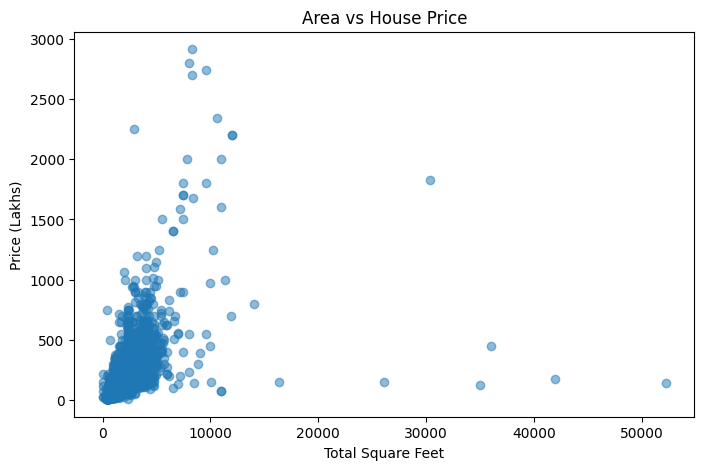


SINGLE LINEAR REGRESSION
MAE : 50.90578699381928
MSE : 14226.18461481777
RMSE: 119.27357047903685
R²  : 0.39537656994795967


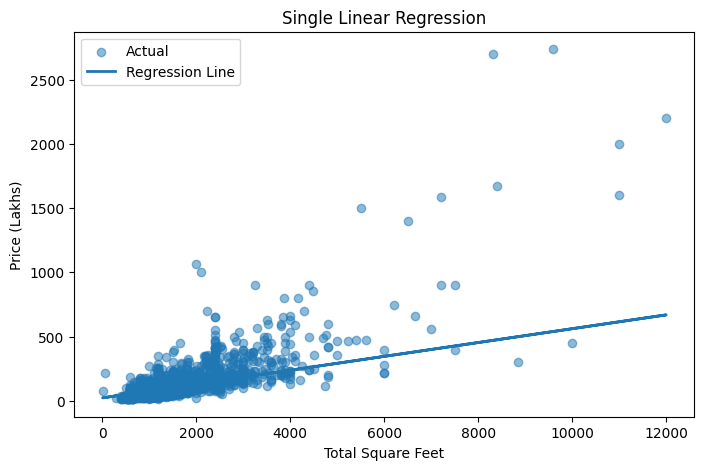


MULTIPLE LINEAR REGRESSION
MAE : 44.89312908437192
MSE : 13438.380199502328
RMSE: 115.9240277056587
R²  : 0.4288588437054668


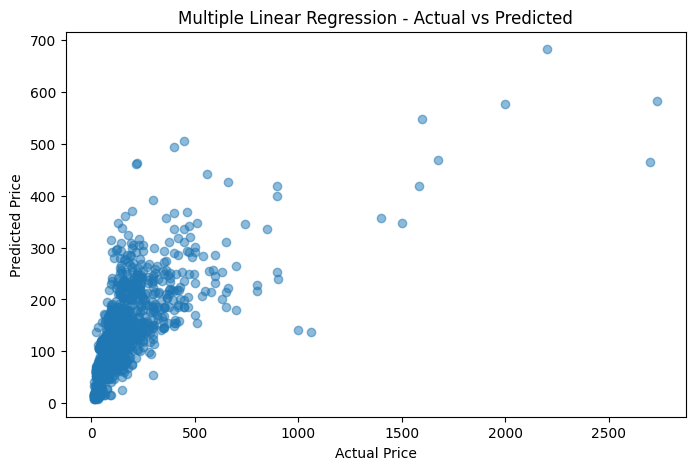


MODEL COMPARISON
                        Model        MAE        RMSE  R2 Score
0    Single Linear Regression  50.905787  119.273570  0.395377
1  Multiple Linear Regression  44.893129  115.924028  0.428859


In [1]:
# ==========================================
# SINGLE & MULTIPLE LINEAR REGRESSION
# Bengaluru House Price Dataset
# ==========================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ==========================================
# 2. Load Dataset
# ==========================================

df = pd.read_csv("bengaluru_house_prices.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


# ==========================================
# 3. Data Cleaning
# ==========================================

# Keep only useful numerical columns
df = df[["total_sqft", "bath", "balcony", "price"]].copy()


# Convert total_sqft into numerical value
def convert_sqft(x):

    try:
        if "-" in str(x):
            values = str(x).split("-")
            return (float(values[0]) + float(values[1])) / 2
        else:
            return float(x)
    except:
        return np.nan


df["total_sqft"] = df["total_sqft"].apply(convert_sqft)


# Convert columns to numeric
df["bath"] = pd.to_numeric(df["bath"], errors="coerce")
df["balcony"] = pd.to_numeric(df["balcony"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")


# Remove missing values
df = df.dropna()


print("\nAfter Cleaning:")
print(df.head())

print("\nShape After Cleaning:")
print(df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


# ==========================================
# 4. EDA
# ==========================================

print("\nStatistical Summary:")
print(df.describe())


# ==========================================
# 5. Visualization - Area vs Price
# ==========================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["total_sqft"],
    df["price"],
    alpha=0.5
)

plt.xlabel("Total Square Feet")
plt.ylabel("Price (Lakhs)")
plt.title("Area vs House Price")

plt.show()


# ==========================================
# 6. SINGLE LINEAR REGRESSION
# ==========================================

# One input feature
X_single = df[["total_sqft"]]

# Target
y = df["price"]


# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_single,
    y,
    test_size=0.2,
    random_state=42
)


# Create Model
single_model = LinearRegression()


# Train Model
single_model.fit(X_train, y_train)


# Prediction
y_pred_single = single_model.predict(X_test)


# Evaluation
mae_single = mean_absolute_error(y_test, y_pred_single)

mse_single = mean_squared_error(y_test, y_pred_single)

rmse_single = np.sqrt(mse_single)

r2_single = r2_score(y_test, y_pred_single)


print("\n==========================================")
print("SINGLE LINEAR REGRESSION")
print("==========================================")

print("MAE :", mae_single)
print("MSE :", mse_single)
print("RMSE:", rmse_single)
print("R²  :", r2_single)


# ==========================================
# 7. SINGLE LINEAR REGRESSION GRAPH
# ==========================================

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test["total_sqft"],
    y_test,
    alpha=0.5,
    label="Actual"
)

plt.plot(
    X_test["total_sqft"],
    y_pred_single,
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("Total Square Feet")
plt.ylabel("Price (Lakhs)")
plt.title("Single Linear Regression")

plt.legend()

plt.show()


# ==========================================
# 8. MULTIPLE LINEAR REGRESSION
# ==========================================

# Multiple input features
X_multiple = df[
    ["total_sqft", "bath", "balcony"]
]

# Target
y = df["price"]


# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_multiple,
    y,
    test_size=0.2,
    random_state=42
)


# Create Model
multiple_model = LinearRegression()


# Train Model
multiple_model.fit(X_train, y_train)


# Prediction
y_pred_multiple = multiple_model.predict(X_test)


# Evaluation
mae_multiple = mean_absolute_error(
    y_test,
    y_pred_multiple
)

mse_multiple = mean_squared_error(
    y_test,
    y_pred_multiple
)

rmse_multiple = np.sqrt(mse_multiple)

r2_multiple = r2_score(
    y_test,
    y_pred_multiple
)


print("\n==========================================")
print("MULTIPLE LINEAR REGRESSION")
print("==========================================")

print("MAE :", mae_multiple)
print("MSE :", mse_multiple)
print("RMSE:", rmse_multiple)
print("R²  :", r2_multiple)


# ==========================================
# 9. ACTUAL vs PREDICTED
# ==========================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred_multiple,
    alpha=0.5
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title(
    "Multiple Linear Regression - Actual vs Predicted"
)

plt.show()


# ==========================================
# 10. MODEL COMPARISON
# ==========================================

comparison = pd.DataFrame({

    "Model": [
        "Single Linear Regression",
        "Multiple Linear Regression"
    ],

    "MAE": [
        mae_single,
        mae_multiple
    ],

    "RMSE": [
        rmse_single,
        rmse_multiple
    ],

    "R2 Score": [
        r2_single,
        r2_multiple
    ]
})


print("\n==========================================")
print("MODEL COMPARISON")
print("==========================================")

print(comparison)